# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


## Question

One sentence, then the quantity with units and a time window. Save the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.


### January 2024: Midtown-to-JFK raw-data check

Reproducible exploratory check using the January 2024 NYC yellow-taxi Parquet snapshot.
The file's SHA-256 is checked before analysis.


In [1]:
from pathlib import Path
import hashlib
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

path = data_dir / "yellow_tripdata_2024-01.parquet"
url = (
    "https://d37ci6vzurychx.cloudfront.net/trip-data/"
    "yellow_tripdata_2024-01.parquet"
)

if not path.exists():
    urllib.request.urlretrieve(url, path)

expected_hash = (
    "c4d59da7bbc8abaeeeb1727947ee93d9891"
    "a71acb42854bd80db1571b2030510"
)
actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()

assert actual_hash == expected_hash, "File differs from the documented snapshot."
print("January file downloaded and verified.")

January file downloaded and verified.


In [2]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
]

raw = pd.read_parquet(path, columns=columns)

trips = raw.loc[
    raw["PULocationID"].isin([161, 162, 163, 230])
    & raw["DOLocationID"].eq(132)
    & raw["tpep_pickup_datetime"].ge(pd.Timestamp("2024-01-01"))
    & raw["tpep_pickup_datetime"].lt(pd.Timestamp("2024-02-01"))
].copy()

trips["duration_minutes"] = (
    trips["tpep_dropoff_datetime"]
    - trips["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# These are investigation flags—not automatic deletion rules.
trips["missing_duration"] = trips["duration_minutes"].isna()
trips["nonpositive_duration"] = trips["duration_minutes"].le(0)
trips["over_six_hours"] = trips["duration_minutes"].gt(360)
trips["duplicate_candidate"] = trips.duplicated(
    subset=columns, keep=False
)

display(trips[
    ["missing_duration", "nonpositive_duration",
     "over_six_hours", "duplicate_candidate"]
].sum().to_frame("Flagged rows"))

display(trips.loc[
    trips["over_six_hours"] | trips["duplicate_candidate"]
].head(20))

,Flagged rows
missing_duration,0
nonpositive_duration,0
over_six_hours,13
duplicate_candidate,110


,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,duration_minutes,missing_duration,nonpositive_duration,over_six_hours,duplicate_candidate
33839,2024-01-01 12:23:34,2024-01-01 12:56:03,161,132,32.483333,False,False,False,True
33840,2024-01-01 12:23:34,2024-01-01 12:56:03,161,132,32.483333,False,False,False,True
49372,2024-01-01 16:50:17,2024-01-01 17:27:11,161,132,36.900000,False,False,False,True
49373,2024-01-01 16:50:17,2024-01-01 17:27:11,161,132,36.900000,False,False,False,True
55489,2024-01-01 18:04:29,2024-01-02 17:35:05,230,132,1410.600000,False,False,True,False
91331,2024-01-02 11:56:56,2024-01-02 12:50:45,230,132,53.816667,False,False,False,True
91332,2024-01-02 11:56:56,2024-01-02 12:50:45,230,132,53.816667,False,False,False,True
118292,2024-01-02 17:35:05,2024-01-02 18:46:50,163,132,71.750000,False,False,False,True
118293,2024-01-02 17:35:05,2024-01-02 18:46:50,163,132,71.750000,False,False,False,True
122258,2024-01-02 17:08:45,2024-01-02 18:01:24,161,132,52.650000,False,False,False,True


,January trip duration (minutes)
count,6885.000000
mean,52.674561
std,50.805019
min,5.150000
50%,49.983333
90%,71.183333
95%,76.696667
99%,90.285333
max,1436.100000


Positive-duration trips: 6,885
Trips > 150 minutes (not displayed): 20 (0.29%)
Long trips remain in the dataset and duration summary statistics.


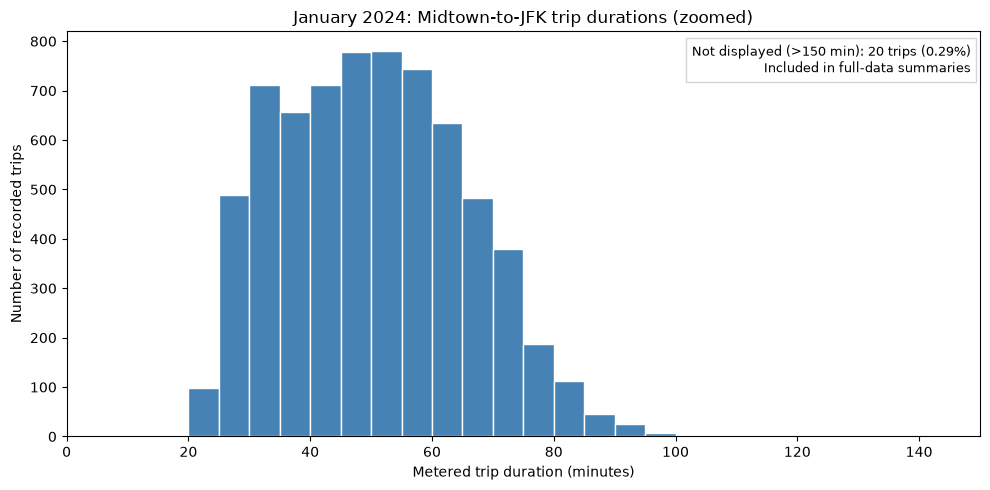

In [3]:
# Summarize positive trip durations without dropping unusually long trips.
positive = trips.loc[trips["duration_minutes"] > 0].copy()

display(
    positive["duration_minutes"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .to_frame("January trip duration (minutes)")
)

# The complete positive-duration dataset is retained for analysis and percentiles.
plot_max_minutes = 150
inside_plot = positive["duration_minutes"].le(plot_max_minutes)
outside_plot = positive["duration_minutes"].gt(plot_max_minutes)
outside_count = int(outside_plot.sum())
valid_count = len(positive)
outside_percent = 100 * outside_count / valid_count if valid_count else 0

print(f"Positive-duration trips: {valid_count:,}")
print(f"Trips > {plot_max_minutes} minutes (not displayed): "
      f"{outside_count:,} ({outside_percent:.2f}%)")
print("Long trips remain in the dataset and duration summary statistics.")

fig, ax = plt.subplots(figsize=(10, 5))
# The histogram shows only the visible range; this is a visualization choice,
# not a filtering rule for the underlying dataset.
visible_durations = positive.loc[inside_plot, "duration_minutes"]
ax.hist(visible_durations, bins=range(0, plot_max_minutes + 6, 5),
        color="steelblue", edgecolor="white")
ax.set_xlim(0, plot_max_minutes)
ax.set_title("January 2024: Midtown-to-JFK trip durations (zoomed)")
ax.set_xlabel("Metered trip duration (minutes)")
ax.set_ylabel("Number of recorded trips")
ax.text(0.99, 0.97,
        f"Not displayed (>150 min): {outside_count:,} trips "
        f"({outside_percent:.2f}%)\n"
        "Included in full-data summaries",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "lightgray", "alpha": 0.95})
fig.tight_layout()

# This saves the real plot when the cell is executed with the January parquet data.
Path("fig").mkdir(exist_ok=True)
fig.savefig("fig/january_duration_histogram.png", dpi=150, bbox_inches="tight")
plt.show()


### January 2024 data check — preliminary findings

The January 2024 Midtown-to-JFK data check contains **6,885 positive-duration trips**,
with a median metered duration of **49.98 minutes** and an empirical 90th percentile
of **71.18 minutes**. These results were recomputed by running the notebook and
independently reproduced by a teammate. This is an initial fixed-allowance benchmark
before February calibration, not a tested recommendation.

The data-quality checks flagged **0 missing durations**, **0 nonpositive durations**,
**13 trips over six hours**, and **110 rows belonging to potential duplicate groups**
based on timestamps and zones. Flagged records remain in the data pending
investigation rather than being automatically deleted.

### January 2024 duration histogram — visualization note

The histogram displays **0–150 minutes** to reveal the distribution of typical
Midtown-to-JFK trip durations. **20 trips (0.29%)** exceed 150 minutes and are
outside the displayed range, but remain in the complete dataset and duration
summaries, including the reported percentiles. The plot is saved as
`fig/january_duration_histogram.png`.

Metered trip duration excludes additional airport procedures and time spent
before entering the taxi, so these results describe the road portion of the journey.


### Days the allowance does not cover (issue #3)

The allowance is meant for ordinary days. A day is flagged if, by 6 pm the day before, it met one of three rules:
(R1) a US federal holiday; (R2) a publicly announced event with street closures inside pickup zones 161, 162, 163
or 230, or on FDR Drive; (R3) an NWS Winter Storm, Blizzard, Ice Storm, Flood or Flash Flood Warning for Manhattan
or Queens. `events.py` lists every candidate day that was checked, flagged or not, with its source. The same rules
and sources apply to January, February and March. Unannounced disruptions, such as the 8 January protest, stay ordinary.


In [4]:
import events

events.candidates()


,date,rule,flagged,what,source
0,2024-01-01,R1,True,New Year's Day,federal holiday (OPM)
1,2024-01-08,R2,False,"Bridge and tunnel protest, 9:40-11:15 am","not announced in advance (NBC New York, ABC7)"
2,2024-01-09,R3,False,"Rain and wind: Flood Watch, High Wind Warning,...",watch only; high wind is not an R3 type; flood...
3,2024-01-10,R3,False,Flood Warning overnight from 9 Jan; Coastal Fl...,"flood warning issued 9:34 pm on 9 Jan, after t..."
4,2024-01-13,R3,False,Coastal Flood Warning,coastal flood is not an R3 type (Iowa Environm...
5,2024-01-15,R1,True,Martin Luther King Jr. Day,federal holiday (OPM)
6,2024-01-16,R3,False,Snow,Winter Weather Advisory only (Iowa Environment...
7,2024-01-19,R3,False,Snow,Winter Weather Advisory only (Iowa Environment...
8,2024-02-13,R3,True,Nor'easter,"Winter Storm Warning issued 4:00 pm on 12 Feb,..."
9,2024-02-17,R3,False,Snow,Winter Weather Advisory only (Iowa Environment...


In [5]:
# January and February only: March is not looked at before it is scored.
feb_path = data_dir / "yellow_tripdata_2024-02.parquet"
if not feb_path.exists():
    urllib.request.urlretrieve(url.replace("2024-01", "2024-02"), feb_path)
assert hashlib.sha256(feb_path.read_bytes()).hexdigest() == (
    "c76c43c18c6c6664080dd920baab4928988d5786a6b65980792ca7cd796f9f20"
), "File differs from the documented snapshot."

feb_raw = pd.read_parquet(feb_path, columns=columns)
feb = feb_raw.loc[
    feb_raw["PULocationID"].isin([161, 162, 163, 230])
    & feb_raw["DOLocationID"].eq(132)
    & feb_raw["tpep_pickup_datetime"].ge(pd.Timestamp("2024-02-01"))
    & feb_raw["tpep_pickup_datetime"].lt(pd.Timestamp("2024-03-01"))
].copy()
feb["duration_minutes"] = (
    feb["tpep_dropoff_datetime"] - feb["tpep_pickup_datetime"]
).dt.total_seconds() / 60

jan_feb = events.flag_days(pd.concat([
    positive[columns + ["duration_minutes"]],
    feb.loc[feb["duration_minutes"] > 0, columns + ["duration_minutes"]],
]))
jan_feb["month"] = jan_feb["tpep_pickup_datetime"].dt.strftime("%Y-%m")
jan_feb["date"] = jan_feb["tpep_pickup_datetime"].dt.date

display(jan_feb.groupby("month").agg(
    trips=("flagged_day", "size"), trips_on_flagged_days=("flagged_day", "sum")
))

daily = (
    jan_feb.groupby(["date", "flagged_day", "flag_rule"])["duration_minutes"]
    .agg(trips="size", median="median", p90=lambda s: s.quantile(0.9))
    .reset_index()
)
ordinary = daily.loc[~daily["flagged_day"]]
display(daily.loc[daily["flagged_day"]].round(1))
print(f"Ordinary days: {len(ordinary)}; median daily median {ordinary['median'].median():.1f} min; "
      f"daily 90th percentile from {ordinary['p90'].quantile(0.1):.1f} to {ordinary['p90'].quantile(0.9):.1f} min "
      f"(10th to 90th percentile of days); median {ordinary['trips'].median():.0f} trips a day.")


,trips,trips_on_flagged_days
month,,
2024-01,6885,629
2024-02,6505,428


,date,flagged_day,flag_rule,trips,median,p90
0,2024-01-01,True,R1,373,43.3,69.7
14,2024-01-15,True,R1,256,42.3,58.7
43,2024-02-13,True,R3,148,34.0,44.6
49,2024-02-19,True,R1,280,41.4,54.4


Ordinary days: 56; median daily median 54.0 min; daily 90th percentile from 49.8 to 81.6 min (10th to 90th percentile of days); median 214 trips a day.


**Flagged days in January and February.** The rules flag four days: 1 and 15 January, 13 and 19 February. They hold
629 of January's 6,885 trips and 428 of February's 6,505 (counted before cleaning; after cleaning, 623 and 423, see the Split section). The flagged days stand out on the fast side: their daily
median runs from 34 to 43 minutes, against 54 minutes on a typical ordinary day, and the snow day (13 February,
schools remote) was the fastest, with a 90th percentile of 44.6 minutes. Holidays and the storm emptied the roads
rather than jamming them. Leaving these days in the January fit and the February offset would pull the allowance
down for ordinary days, so they are removed from both, for the model and the fixed allowance alike.


### Cleaning the records

`taxi.py` loads the three months with the hash check and flags three kinds of record (2026-11-08 entry):
reversal copies (a voided payment: same times, zones and distance as a real trip, with a negative fare),
non-positive durations, and meters left running over six hours. Reversal copies and non-positive durations
are dropped; trips over six hours are left out of the fit and the main score and come back in a sensitivity.
March is used only for these prespecified record-quality checks: its durations are computed to flag
non-positive and over-six-hour records, and only the counts are shown. March is not used for fitting,
calibration, choosing features, or comparing the methods until it is scored once.


In [6]:
import taxi

records = taxi.records()
records["month"] = records["tpep_pickup_datetime"].dt.strftime("%Y-%m")
display(records.groupby("month").agg(
    records=("flag_reversal", "size"),
    reversal_copies=("flag_reversal", "sum"),
    non_positive=("flag_nonpositive", "sum"),
    over_six_hours=("flag_over_6h", "sum"),
))


,records,reversal_copies,non_positive,over_six_hours
month,,,,
2024-01,6885,55,0,13
2024-02,6505,87,0,9
2024-03,8336,124,1,15


## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


In [7]:
trips = taxi.trips(records)

display(pd.DataFrame(taxi.SPLIT, index=["from", "to (exclusive)"]).T)
display(trips.groupby("split", sort=False).agg(
    trips=("flagged_day", "size"),
    ordinary_day_trips=("flagged_day", lambda s: int((~s).sum())),
))


,from,to (exclusive)
fit,2024-01-01,2024-02-01
calibrate,2024-02-01,2024-03-01
test,2024-03-01,2024-04-01


,trips,ordinary_day_trips
split,,
fit,6817,6194
calibrate,6409,5986
test,8196,7635


**Split.** Fit on January, calibrate the additive offset on February, score March once (2026-11-08 entry).
Fit and calibration use ordinary days only (2026-11-07 entry). March is scored on ordinary days and on all days.


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


In [8]:
# Fixed baseline: fit January, calibrate February; do not read March outcomes here.
from baseline import january_p90, calibrate_fixed_p90
import scoring

jan_ordinary = trips.loc[
    (trips["split"] == "fit") & (~trips["flagged_day"]), "duration_minutes"
].to_numpy()
feb_ordinary = trips.loc[
    (trips["split"] == "calibrate") & (~trips["flagged_day"]), "duration_minutes"
].to_numpy()

jan_allowance = january_p90(jan_ordinary)
feb_offset, fixed_allowance = calibrate_fixed_p90(jan_allowance, feb_ordinary)

print(f"January ordinary-day sample: {len(jan_ordinary):,} trips")
print(f"February ordinary-day sample: {len(feb_ordinary):,} trips")
print(f"January fixed P90: {jan_allowance:.2f} minutes")
print(f"February additive offset: {feb_offset:+.2f} minutes")
print(f"Frozen fixed baseline: {fixed_allowance:.2f} minutes")
print(f"February calibrated coverage (diagnostic): {scoring.coverage(feb_ordinary, fixed_allowance):.1%}")


January ordinary-day sample: 6,194 trips
February ordinary-day sample: 5,986 trips
January fixed P90: 71.28 minutes
February additive offset: +4.72 minutes
Frozen fixed baseline: 76.00 minutes
February calibrated coverage (diagnostic): 90.0%


### Why February coverage is 90%

The fixed allowance starts with January's ordinary-day 90th percentile (71.28 minutes). February calibration adds the difference between February's and January's 90th percentiles (+4.72 minutes), yielding a frozen allowance of 76.00 minutes. Because this is exactly February's ordinary-day 90th percentile, approximately 90% February coverage is achieved by construction. March remains the independent held-out evaluation.

## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


### Quantile regression

For a trip picked up in hour $h$, on day $d$, in zone $z$, the model is

$$Q_{0.9}(T \mid h, d, z) = \alpha_{w(d),\,b(h)} + \gamma_d + \delta_z, \qquad \gamma_{\text{Mon}} = \gamma_{\text{Sat}} = \delta_{161} = 0,$$

fit on January ordinary-day trips by minimising the 0.9 quantile loss (`model.py`, 2026-11-10 entry).

- $\alpha_{w,b}$ is the 90th-percentile trip time, in minutes, for hour cell $b$ on a weekday ($w$ = weekday, a Monday from
  zone 161) or at the weekend (a Saturday from zone 161). Weekdays and weekends each have their own hourly profile,
  because the weekday rush has no weekend counterpart. The hour cells are the single hours from 4 am to 7 pm and one
  night cell for 8 pm to 4 am, the hours with fewer than 100 January trips each.
- $\gamma_d$ is the minutes added for the day: Tuesday to Friday against Monday, Sunday against Saturday.
- $\delta_z$ is the minutes added for the pickup zone, against zone 161.

The allowance is $Q_{0.9} + c$, where $c$ is the 90th percentile of February ordinary-day errors (actual minus
predicted), the same rule as the fixed allowance. That makes 42 coefficients and one offset.

The assumption trusted least is the single offset $c$: it assumes February differs from January by the same number
of minutes at every hour. The second is that day and zone shift a whole profile up or down by a constant.

In [9]:
# Quantile regression: fit January, calibrate February; do not read March outcomes here.
import evaluation
import model

jan_fit = trips.loc[(trips["split"] == "fit") & (~trips["flagged_day"])]
feb_cal = trips.loc[(trips["split"] == "calibrate") & (~trips["flagged_day"])]

qr_params = model.fit(jan_fit)
qr_offset, qr_feb_allowance = model.calibrate(qr_params, feb_cal)
qr_feb_raw = model.predict(qr_params, feb_cal)

print(f"January fit: {len(jan_fit):,} trips, {len(qr_params)} coefficients")
print(f"Smallest cell: {int(model.design(jan_fit).iloc[:, :34].sum().min())} January trips")
print(f"January coverage (in sample): {scoring.coverage(jan_fit['duration_minutes'], model.predict(qr_params, jan_fit)):.3f}")
print(f"February coverage before offset: {scoring.coverage(feb_cal['duration_minutes'], qr_feb_raw):.3f}")
print(f"February offset: {qr_offset:+.2f} minutes")
print(f"February coverage after offset: {scoring.coverage(feb_cal['duration_minutes'], qr_feb_allowance):.3f}")
print(f"Calibrated February allowances: {qr_feb_allowance.min():.1f} to {qr_feb_allowance.max():.1f} minutes")
print("February quantile loss (calibration month, not a test): "
      f"quantile regression {scoring.quantile_loss(feb_cal['duration_minutes'], qr_feb_allowance):.3f}, "
      f"fixed allowance {scoring.quantile_loss(feb_cal['duration_minutes'], fixed_allowance):.3f}")

profile = pd.DataFrame(
    {w: [qr_params[f"{w}_{c}"] for c in model.CELLS] for w in ("weekday", "weekend")}, index=model.CELLS
)
display(profile.round(1).T)
display(qr_params.iloc[34:].round(1).to_frame("minutes added").T)

January fit: 6,194 trips, 42 coefficients
Smallest cell: 27 January trips
January coverage (in sample): 0.897
February coverage before offset: 0.832
February offset: +3.83 minutes
February coverage after offset: 0.900
Calibrated February allowances: 30.8 to 88.4 minutes
February quantile loss (calibration month, not a test): quantile regression 2.259, fixed allowance 3.462


,night,04,05,06,07,08,09,10,11,12,13,14,15,16,17,18,19
weekday,42.2,34.7,38.5,42.5,63.0,62.3,65.2,62.4,62.5,64.5,65.9,68.4,75.2,75.0,72.4,58.0,44.8
weekend,44.5,38.3,40.4,45.5,35.9,36.6,38.8,37.6,39.8,44.2,51.2,55.8,61.5,61.7,61.3,57.1,49.4


,Tue,Wed,Thu,Fri,Sun,zone_162,zone_163,zone_230
minutes added,2.9,4.7,6.6,-0.5,-4.3,-4.6,2.8,2.8


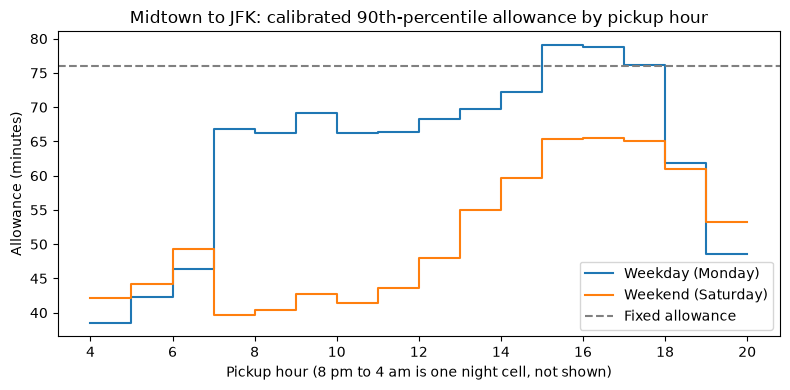

In [10]:
# The frozen allowances by pickup hour: Monday and Saturday from zone 161, against the fixed allowance.
hours = [f"{h:02d}" for h in range(4, 20)]
fig, ax = plt.subplots(figsize=(8, 4))
for w, label in (("weekday", "Weekday (Monday)"), ("weekend", "Weekend (Saturday)")):
    ax.step(range(4, 21), list(profile.loc[hours, w] + qr_offset) + [profile.loc["19", w] + qr_offset],
            where="post", label=label)
ax.axhline(fixed_allowance, color="gray", linestyle="--", label="Fixed allowance")
ax.set_xticks(range(4, 21, 2))
ax.set_xlabel("Pickup hour (8 pm to 4 am is one night cell, not shown)")
ax.set_ylabel("Allowance (minutes)")
ax.set_title("Midtown to JFK: calibrated 90th-percentile allowance by pickup hour")
ax.legend()
fig.tight_layout()
fig.savefig("fig/model_hour_profile.png", dpi=150)
plt.show()

In [11]:
# Structure check on January only: hold out one day at a time, fit on the other days, score the held-out day.
loo_both = model.leave_one_day_out(jan_fit)
loo_main = model.leave_one_day_out(jan_fit, by_day_type=False)
loo_diff = loo_both - loo_main

print(f"Held-out-day quantile loss, mean over {len(loo_both)} January days")
print(f"  hour, day and zone added together:       {loo_main.mean():.3f}")
print(f"  separate weekday and weekend profiles:   {loo_both.mean():.3f}")
print(f"  difference: {loo_diff.mean():+.3f} (standard error {loo_diff.sem():.3f}), "
      f"lower on {int((loo_diff < 0).sum())} of {len(loo_diff)} days")

Held-out-day quantile loss, mean over 29 January days
  hour, day and zone added together:       2.084
  separate weekday and weekend profiles:   1.956
  difference: -0.128 (standard error 0.033), lower on 24 of 29 days


In [12]:
# The two other structures named in the 2026-11-10 model entry, on the same held-out January days.
import numpy as np
import statsmodels.api as sm


def seven_day_design(frame):
    """One value per hour for each of the seven days (168 cells), plus zone shifts."""
    pickup = frame["tpep_pickup_datetime"]
    cell = pd.Categorical(pickup.dt.hour.to_numpy() * 7 + pickup.dt.day_of_week.to_numpy(), categories=range(168))
    zone = frame["PULocationID"].to_numpy()
    return np.column_stack([pd.get_dummies(cell, dtype=float).to_numpy()]
                           + [(zone == z).astype(float) for z in model.ZONES[1:]])


def smooth_design(frame):
    """Three sine and cosine pairs over the day, a separate set for weekends, day and zone shifts."""
    pickup = frame["tpep_pickup_datetime"]
    x = (pickup.dt.hour + pickup.dt.minute / 60).to_numpy()
    day, zone = pickup.dt.day_of_week.to_numpy(), frame["PULocationID"].to_numpy()
    waves = np.column_stack([f(2 * np.pi * k * x / 24) for k in (1, 2, 3) for f in (np.sin, np.cos)])
    return np.column_stack([np.ones(len(x)), waves, waves * (day >= 5)[:, None]]
                           + [(day == d).astype(float) for d in range(1, 7)]
                           + [(zone == z).astype(float) for z in model.ZONES[1:]])


jan_y = jan_fit["duration_minutes"].to_numpy()
jan_date = jan_fit["tpep_pickup_datetime"].dt.date.to_numpy()
for name, make in (("a profile for each of the seven days", seven_day_design),
                   ("sines and cosines, weekday and weekend", smooth_design)):
    X = make(jan_fit)
    held_loss = []
    for d in np.unique(jan_date):
        held = jan_date == d
        beta = sm.QuantReg(jan_y[~held], X[~held]).fit(q=0.90, max_iter=10000).params
        held_loss.append(scoring.quantile_loss(jan_y[held], X[held] @ beta))
    print(f"  {name + ':':40s} {np.mean(held_loss):.3f}")

  a profile for each of the seven days:    2.143


  sines and cosines, weekday and weekend:  1.942


In [13]:
# February by departure period (the proposal's Revisit check) and by day type, with each month's own 90th percentile.
def period_of(frame):
    return pd.cut(
        frame["tpep_pickup_datetime"].dt.hour, [-1, 3, 9, 15, 19, 23],
        labels=["midnight-4 am", "4-10 am", "10 am-4 pm", "4-8 pm", "8 pm-midnight"],
    )

def day_type_of(frame):
    return np.where(frame["tpep_pickup_datetime"].dt.day_of_week >= 5, "weekend", "weekday")

feb_checked = feb_cal.assign(
    period=period_of(feb_cal),
    day_type=day_type_of(feb_cal),
    qr=feb_cal["duration_minutes"].to_numpy() <= qr_feb_allowance,
    qr_raw=feb_cal["duration_minutes"].to_numpy() <= qr_feb_raw,
    fixed=feb_cal["duration_minutes"].to_numpy() <= fixed_allowance,
)
for key, jan_key in (("period", period_of(jan_fit)), ("day_type", day_type_of(jan_fit))):
    feb_group = feb_checked.groupby(key, observed=True)
    jan_group = jan_fit.groupby(jan_key, observed=True)
    display(pd.DataFrame({
        "February trips": feb_group.size(),
        "January P90 (min)": jan_group["duration_minutes"].quantile(0.9).round(1),
        "February P90 (min)": feb_group["duration_minutes"].quantile(0.9).round(1),
        "coverage: quantile regression, before offset": feb_group["qr_raw"].mean().round(3),
        "coverage: quantile regression": feb_group["qr"].mean().round(3),
        "coverage: fixed allowance": feb_group["fixed"].mean().round(3),
    }))

# The 4-8 pm weekday 90th percentile, week by week (ISO weeks; the first and last weeks of a month are partial).
for name, frame in (("January", jan_fit), ("February", feb_cal)):
    peak = frame.loc[(period_of(frame) == "4-8 pm") & (day_type_of(frame) == "weekday")]
    weekly = peak.groupby(peak["tpep_pickup_datetime"].dt.isocalendar().week)["duration_minutes"].quantile(0.9)
    print(f"{name}, weekday 4-8 pm P90 by week: " + ", ".join(f"{v:.1f}" for v in weekly))

,February trips,January P90 (min),February P90 (min),"coverage: quantile regression, before offset",coverage: quantile regression,coverage: fixed allowance
midnight-4 am,70,42.8,42.2,0.929,0.943,1.000
4-10 am,1277,58.2,57.2,0.897,0.941,0.991
10 am-4 pm,3111,71.8,74.6,0.860,0.920,0.912
4-8 pm,1387,75.9,85.6,0.709,0.816,0.774
8 pm-midnight,141,47.3,50.1,0.794,0.894,1.000


,February trips,January P90 (min),February P90 (min),"coverage: quantile regression, before offset",coverage: quantile regression,coverage: fixed allowance
weekday,4124,73.2,80.3,0.812,0.877,0.857
weekend,1862,52.0,54.9,0.878,0.951,0.995


January, weekday 4-8 pm P90 by week: 73.8, 79.1, 80.3, 80.4, 71.0
February, weekday 4-8 pm P90 by week: 79.2, 81.9, 91.8, 79.9, 96.0


In [14]:
# Uncertainty of the allowance: resample whole days (seed 600), refit on January, recalibrate on February.
boot_allowance, boot_offset, boot_skipped = model.bootstrap_allowances(jan_fit, feb_cal, draws=300, seed=600)
allowance_se = pd.Series(boot_allowance.std(axis=0), index=feb_cal.index)

rng = np.random.default_rng(600)
boot_fixed = np.array([
    np.quantile(evaluation.resample_days(feb_cal, rng)["duration_minutes"], 0.90) for _ in range(300)
])

print(f"Draws used: {len(boot_offset)} of 300 ({boot_skipped} skipped for an empty cell)")
print(f"Standard error of a trip's calibrated allowance: median {allowance_se.median():.1f} minutes "
      f"(range {allowance_se.min():.1f} to {allowance_se.max():.1f})")
print(allowance_se.groupby(day_type_of(feb_cal)).median().round(1).to_frame("median standard error (min)").T.to_string())
print(f"Quantile regression offset {qr_offset:+.2f}: standard error {boot_offset.std():.1f}, "
      f"90% interval {np.quantile(boot_offset, 0.05):+.1f} to {np.quantile(boot_offset, 0.95):+.1f}")
print(f"Fixed allowance {fixed_allowance:.2f}: standard error {boot_fixed.std():.1f}, "
      f"90% interval {np.quantile(boot_fixed, 0.05):.1f} to {np.quantile(boot_fixed, 0.95):.1f}")

# Why days and not trips: the offset's standard error with the model held fixed, resampled both ways.
feb_error = feb_cal.assign(error=feb_cal["duration_minutes"].to_numpy() - qr_feb_raw)
by_days = [np.quantile(evaluation.resample_days(feb_error, rng)["error"], 0.90) for _ in range(300)]
by_trips = [np.quantile(rng.choice(feb_error["error"].to_numpy(), len(feb_error)), 0.90) for _ in range(300)]
print(f"Offset standard error, model held fixed: {np.std(by_days):.2f} resampling days, "
      f"{np.std(by_trips):.2f} resampling trips")

Draws used: 300 of 300 (0 skipped for an empty cell)
Standard error of a trip's calibrated allowance: median 2.7 minutes (range 2.0 to 5.9)
                             weekday  weekend
median standard error (min)      2.6      3.4
Quantile regression offset +3.83: standard error 1.9, 90% interval +1.8 to +7.7
Fixed allowance 76.00: standard error 3.2, 90% interval 70.0 to 80.9
Offset standard error, model held fixed: 1.60 resampling days, 0.35 resampling trips


**What the model shows, before March.** On January the 42 coefficients cover 89.7% of trips in sample. February ran
slower: the uncalibrated model covers 83.2%, and the offset of +3.83 minutes brings it to 90.0%. The frozen allowances
run from 30.8 to 88.4 minutes, against the fixed 76.00.

*Structure.* Holding out one January day at a time, separate weekday and weekend profiles score 1.956 against 2.084
for hour, day and zone added together, lower on 24 of 29 days. The structure was chosen on that January comparison.
February's numbers were seen beside it and point the same way: on February, the calibration month, the loss is 2.259
against 3.462 for the fixed allowance. That is not a test, since both offsets were set on the same trips.

*Uncertainty.* Trips on one day share its traffic, so whole days are resampled (300 draws, seed 600). A trip's
allowance has a standard error of about 2.7 minutes (2.6 on weekdays, 3.4 at weekends, at most 5.9). The model's offset
of +3.83 has a standard error of 1.9 minutes; the fixed allowance of 76.00 is February's 90th percentile, so its
standard error, 3.2 minutes, is that percentile's day-to-day spread.

*Where February coverage falls short.* After calibration both methods fall short from 4 to 8 pm: 81.6% for the model,
77.4% for the fixed allowance. By day type the model covers 87.7% on weekdays and 95.1% at weekends (fixed: 85.7% and
99.5%). The pattern points to slow February afternoons rather than missing predictors, though missing
predictors cannot be ruled out. January's 4 to 8 pm 90th percentile was 75.9 minutes and February's was 85.6,
while the other periods moved by 3 minutes or less. The rise is not spread evenly: three of February's five weeks had a
weekday 4 to 8 pm 90th percentile of 79 to 82 minutes, as in mid-January, and the weeks of 12 and 26 February had 92
and 96. One offset for the whole month cannot follow a few slow afternoons. The offset rule is kept as the proposal
set it, for both methods, and March coverage will be reported by period and by day type.


### March: the held-out score

March is scored once, with both methods frozen (2026-11-10 scoring entry). The primary outcome is the mean quantile
loss on ordinary days, in weighted minutes per trip: a minute late counts 0.9, a minute unused counts 0.1. The interval
for the difference resamples whole March days, the same days for both methods (10,000 draws, seed 600). If that interval includes zero, no winner is declared: the
data are not enough to tell the methods apart, which is not evidence that they are equally good.

Until that run, `SCORE_MARCH` is `False` and these cells print a notice instead. The scoring run changes that one line
and nothing else.

In [15]:
SCORE_MARCH = False  # set to True once, for the single scoring run (2026-11-10 scoring entry)

if not SCORE_MARCH:
    print("March not scored yet: SCORE_MARCH is False, and no March outcome is read.")
else:
    # March, scored once with the frozen methods (2026-11-10 scoring entry).
    march = trips.loc[trips["split"] == "test"]
    march_ordinary = march.loc[~march["flagged_day"]]


    def allowances(frame, params=qr_params, offset=qr_offset, fixed=fixed_allowance):
        return {
            "quantile regression": model.predict(params, frame) + offset,
            "fixed allowance": np.full(len(frame), fixed),
        }


    march_scores = pd.concat({
        name: evaluation.score_table(frame["duration_minutes"], allowances(frame))
        for name, frame in {
            "ordinary days (primary)": march_ordinary,
            "all days": march,
            "flagged days": march.loc[march["flagged_day"]],
        }.items()
    })
    display(march_scores.round(3))

March not scored yet: SCORE_MARCH is False, and no March outcome is read.


In [16]:
if not SCORE_MARCH:
    print("March not scored yet: SCORE_MARCH is False, and no March outcome is read.")
else:
    # The primary comparison: fixed allowance minus quantile regression, with a 90% interval from resampled days.
    ordinary_allowances = allowances(march_ordinary)
    loss_qr = evaluation.trip_loss(march_ordinary["duration_minutes"], ordinary_allowances["quantile regression"])
    loss_fixed = evaluation.trip_loss(march_ordinary["duration_minutes"], ordinary_allowances["fixed allowance"])

    difference = loss_fixed.mean() - loss_qr.mean()
    boot_difference = evaluation.day_bootstrap_difference(
        march_ordinary["tpep_pickup_datetime"], loss_fixed, loss_qr, draws=10_000, seed=600
    )
    low, high = np.quantile(boot_difference, [0.05, 0.95])
    daily = pd.DataFrame({"qr": loss_qr, "fixed": loss_fixed}).groupby(
        march_ordinary["tpep_pickup_datetime"].dt.date.to_numpy()
    ).mean()

    print(f"March ordinary days: {len(march_ordinary):,} trips on {len(daily)} days")
    print(f"Mean loss: quantile regression {loss_qr.mean():.3f}, fixed allowance {loss_fixed.mean():.3f}")
    print(f"Difference (fixed minus quantile regression): {difference:+.3f} weighted minutes per trip, "
          f"90% interval {low:+.3f} to {high:+.3f}")
    print(f"Quantile regression has the lower loss on {int((daily['qr'] < daily['fixed']).sum())} of {len(daily)} days")
    print("Result: " + ("quantile regression preferred" if low > 0 else "fixed allowance preferred" if high < 0 else "no clear winner"))

March not scored yet: SCORE_MARCH is False, and no March outcome is read.


In [17]:
if not SCORE_MARCH:
    print("March not scored yet: SCORE_MARCH is False, and no March outcome is read.")
else:
    # Where each method wins: March ordinary days by departure period and by day type.
    march_checked = march_ordinary.assign(
        period=period_of(march_ordinary),
        day_type=day_type_of(march_ordinary),
        late_qr=march_ordinary["duration_minutes"].to_numpy() > ordinary_allowances["quantile regression"],
        late_fixed=march_ordinary["duration_minutes"].to_numpy() > ordinary_allowances["fixed allowance"],
        loss_qr=loss_qr,
        loss_fixed=loss_fixed,
    )
    for key in ("period", "day_type"):
        group = march_checked.groupby(key, observed=True)
        display(pd.DataFrame({
            "trips": group.size(),
            "coverage: quantile regression": (1 - group["late_qr"].mean()).round(3),
            "coverage: fixed allowance": (1 - group["late_fixed"].mean()).round(3),
            "mean loss: quantile regression": group["loss_qr"].mean().round(3),
            "mean loss: fixed allowance": group["loss_fixed"].mean().round(3),
        }))

March not scored yet: SCORE_MARCH is False, and no March outcome is read.


In [18]:
if not SCORE_MARCH:
    print("March not scored yet: SCORE_MARCH is False, and no March outcome is read.")
else:
    # Sensitivities (they do not change the preferred method).
    # Over-six-hour trips put back, ordinary days.
    with_long = taxi.trips(records, drop_over_6h=False)
    with_long = with_long.loc[(with_long["split"] == "test") & (~with_long["flagged_day"])]
    print(f"Over-six-hour trips put back: {len(with_long) - len(march_ordinary)} more trips")
    display(evaluation.score_table(with_long["duration_minutes"], allowances(with_long)).round(3))

    # A 95% target: refit and recalibrate both methods at 0.95 on January and February, score with the 0.95/0.05 loss.
    qr_params_95 = model.fit(jan_fit, tau=0.95)
    qr_offset_95, _ = model.calibrate(qr_params_95, feb_cal, tau=0.95)
    jan_p95 = float(np.quantile(jan_ordinary, 0.95))
    fixed_95 = jan_p95 + scoring.february_additive_offset(feb_ordinary, jan_p95, tau=0.95)
    print(f"95% target: quantile regression offset {qr_offset_95:+.2f}, fixed allowance {fixed_95:.2f} minutes")
    display(evaluation.score_table(
        march_ordinary["duration_minutes"], allowances(march_ordinary, qr_params_95, qr_offset_95, fixed_95), tau=0.95
    ).round(3))

March not scored yet: SCORE_MARCH is False, and no March outcome is read.


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
